## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


The point estimate of the ATE is -0.01, and based on these results I would prefer not to get the intra aortic balloon pump since it has a lower survival rate.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

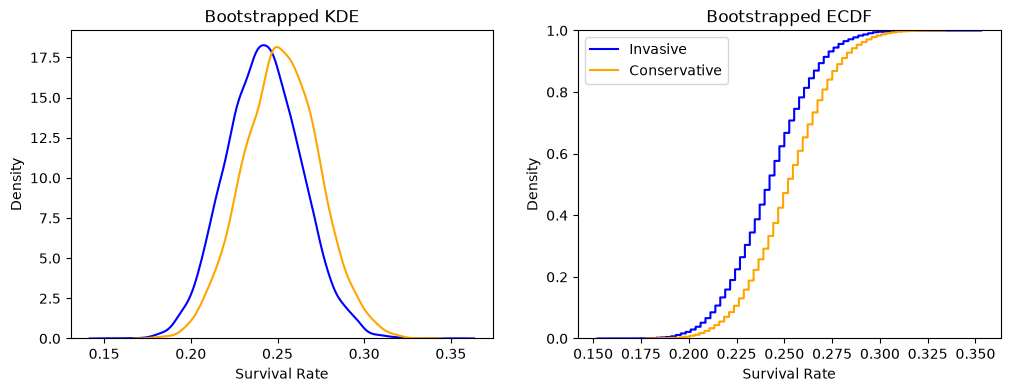

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

Both groups show very similar distributions that look close to normal with nearly the same variance, but a slightly lower mean for the invasive group.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

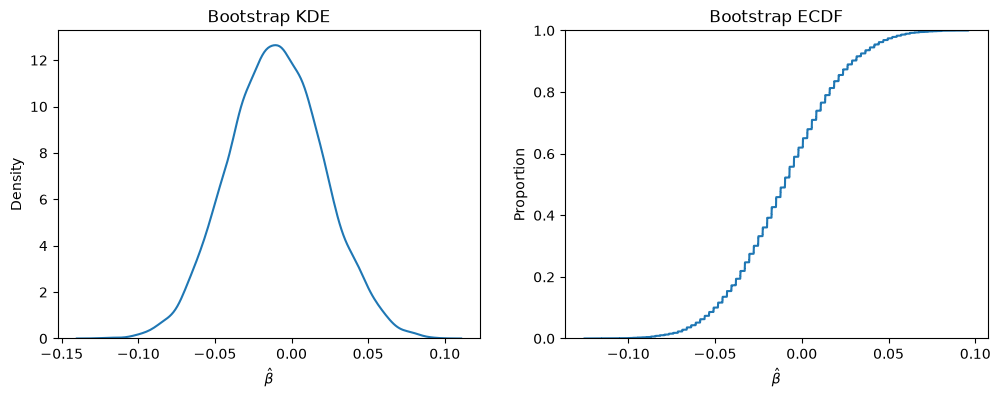

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


Yes, the shape is roughly a bell curve and the range is ~-0.13 to 0.10, though the median is slightly below 0.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06111361  0.04182016]
95% CI: [-0.0688787   0.05206335]
99% CI: [-0.08688032  0.06763324]


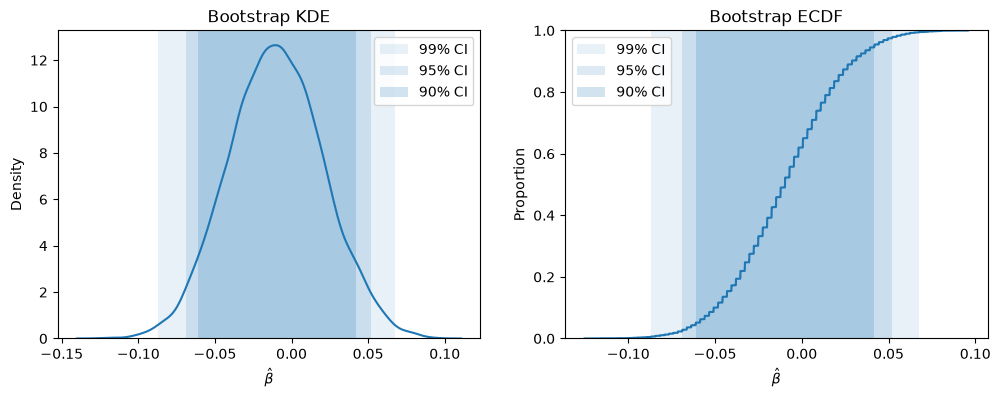

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

Zero falls inside all three intervals, -0.061 to 0.042 at 90 percent, -0.069 to 0.052 at 95 percent, and -0.087 to 0.068 at 99 percent. So we fail to reject the null hypothesis that the effect size is zero at all three levels, and reject it at none.

**6.** What have we learned about inserting balloons into hearts?

We learned that it doesn't do very much as far as the survival rate is concerned. The point estimate of the effect is slightly negative, but zero lies inside all three confidence intervals, so we fail to reject the null hypothesis of no effect at the 90, 95, or 99 percent level. Given that the pump is the more invasive option, which probably brings other costs like a longer recovery time, the data suggest it is not worth it.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

### Section 1

In [8]:
df = pd.read_csv('./data/diabetes.csv')
print(pd.crosstab(df['treatment'], df['outcome']), '\n')
df['success'] = (df['outcome'] == 'success').astype(int)
df.groupby('treatment')['success'].mean()

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 



treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: success, dtype: float64

Lifestyle has an average success rate of ~53 percent, met has ~48 percent, and rosi has the highest at ~61 percent.

### Section 2

In [9]:
R = 10_000

df_met = df.loc[ df['treatment'] == 'met',:]
df_rosi = df.loc[ df['treatment'] == 'rosi',:]
df_lifestyle = df.loc[ df['treatment'] == 'lifestyle',:]

outcome_met = []
outcome_rosi = []
outcome_lifestyle = []

for t in range(R):
    outcome_met.append( df_met.sample( frac = 1.0, replace = True )['success'].mean() )
    outcome_rosi.append( df_rosi.sample( frac = 1.0, replace = True )['success'].mean() )
    outcome_lifestyle.append( df_lifestyle.sample( frac = 1.0, replace = True )['success'].mean() )

### Section 3

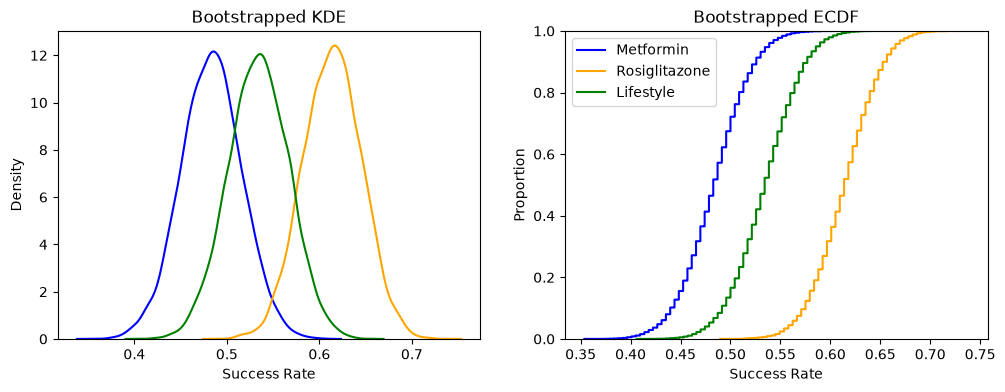

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='Metformin', color='blue', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[0])
sns.kdeplot(outcome_lifestyle, label='Lifestyle', color='green', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_met, label='Metformin', color='blue', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[1])
sns.ecdfplot(outcome_lifestyle, label='Lifestyle', color='green', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')

plt.legend()
plt.show()

All three form close to normal distributions with similar variance and different means. Metformin has the lowest, Lifestyle is in the middle, and Rosiglitazone has the highest. In the KDE, Lifestyle overlaps substantially with both Metformin and Rosiglitazone, but Metformin and Rosiglitazone have little overlap.

### Section 4

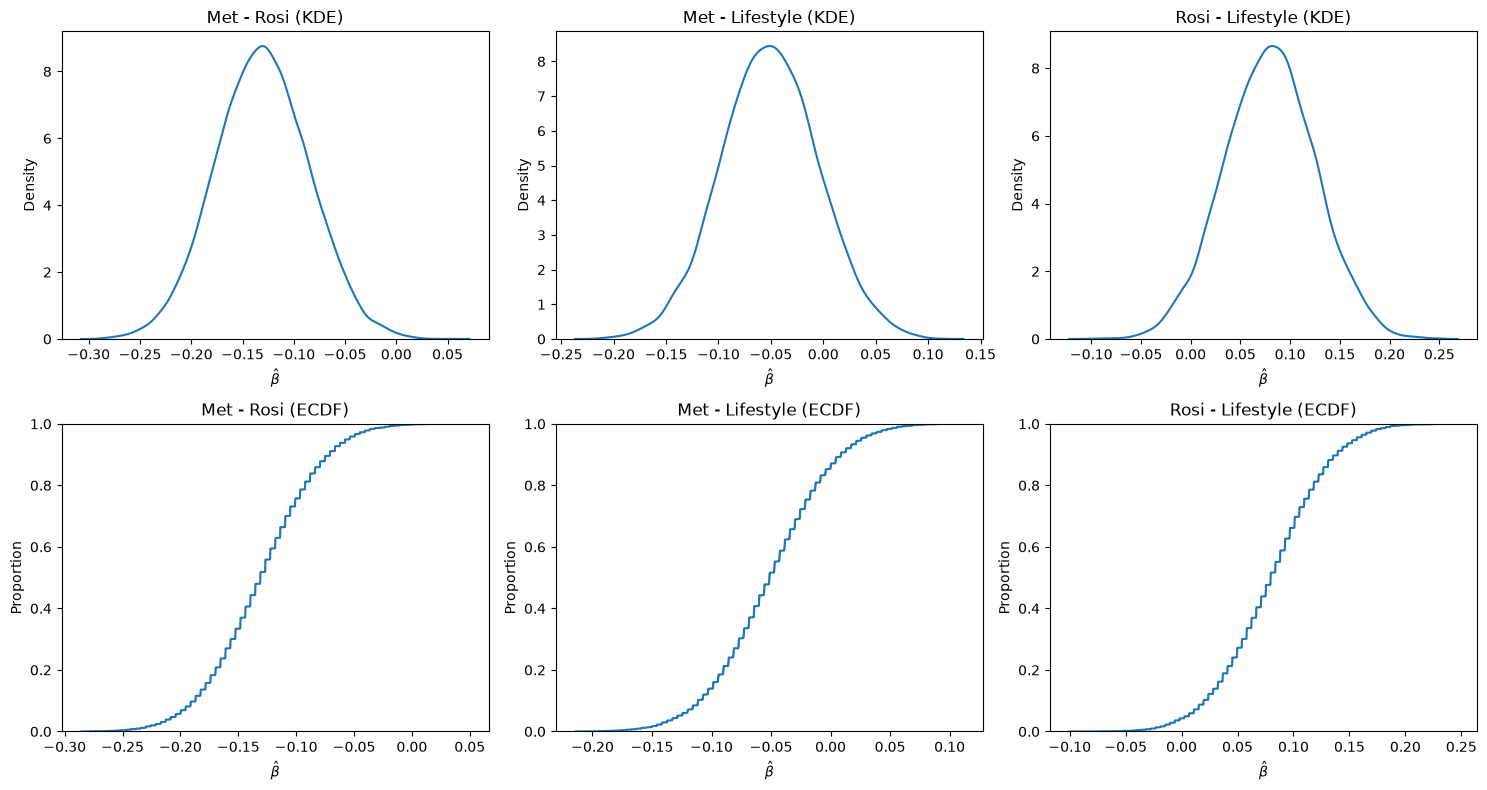

In [11]:
ate_met_rosi = np.array(outcome_met) - np.array(outcome_rosi)
ate_met_lifestyle = np.array(outcome_met) - np.array(outcome_lifestyle)
ate_rosi_lifestyle = np.array(outcome_rosi) - np.array(outcome_lifestyle)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))

sns.kdeplot(ate_met_rosi, ax=ax[0, 0]).set(title='Met - Rosi (KDE)', xlabel=r"$\hat{\beta}$")
sns.kdeplot(ate_met_lifestyle, ax=ax[0, 1]).set(title='Met - Lifestyle (KDE)', xlabel=r"$\hat{\beta}$")
sns.kdeplot(ate_rosi_lifestyle, ax=ax[0, 2]).set(title='Rosi - Lifestyle (KDE)', xlabel=r"$\hat{\beta}$")

sns.ecdfplot(ate_met_rosi, ax=ax[1, 0]).set(title='Met - Rosi (ECDF)', xlabel=r"$\hat{\beta}$", ylabel='Proportion')
sns.ecdfplot(ate_met_lifestyle, ax=ax[1, 1]).set(title='Met - Lifestyle (ECDF)', xlabel=r"$\hat{\beta}$", ylabel='Proportion')
sns.ecdfplot(ate_rosi_lifestyle, ax=ax[1, 2]).set(title='Rosi - Lifestyle (ECDF)', xlabel=r"$\hat{\beta}$", ylabel='Proportion')

plt.tight_layout()
plt.show()

### Section 5

In [12]:
effects = {
    'Met - Rosi': ate_met_rosi,
    'Met - Lifestyle': ate_met_lifestyle,
    'Rosi - Lifestyle': ate_rosi_lifestyle,
}

for name, vals in effects.items():
    ci90 = np.quantile(vals, [.05, .95])
    ci95 = np.quantile(vals, [.025, .975])
    ci99 = np.quantile(vals, [.005, .995])
    print(name)
    print(f'90% CI: {ci90}')
    print(f'95% CI: {ci95}')
    print(f'99% CI: {ci99}')
    print()

Met - Rosi
90% CI: [-0.20414015 -0.05370357]
95% CI: [-0.21712761 -0.04067957]
99% CI: [-0.2471511  -0.01056312]

Met - Lifestyle
90% CI: [-0.12853854  0.02582523]
95% CI: [-0.14165193  0.04273504]
99% CI: [-0.17160367  0.06874466]

Rosi - Lifestyle
90% CI: [0.00660284 0.156579  ]
95% CI: [-0.01039947  0.16949121]
99% CI: [-0.03611395  0.19513224]



For Met vs Rosi, zero is outside all three intervals, with the 95 percent interval running -0.217 to -0.041, so the difference is significant at every level. For Met vs Lifestyle, zero sits inside all three intervals, so there is no significant difference. For Rosi vs Lifestyle, zero is outside the 90 percent interval, which runs 0.007 to 0.157, but inside the 95 and 99 percent intervals, so that difference is significant only at the 90 percent level. Rosi looks like the most effective treatment, clearly better than Met and better than Lifestyle at the 90 percent level.

### Section 6

### Report: Evidence on the Three Interventions

This report summarizes the findings from a randomized trial of three interventions for pre-diabetic patients, Metformin, Rosiglitazone, and Lifestyle, where success means the patient did not progress to full diabetes. The 699 patients were split across the three arms, 232 in Metformin, 233 in Rosiglitazone, and 234 in Lifestyle. Assignment to each group was random, so differences in success rates estimate average treatment effects. The method draws 10,000 bootstrap resamples within each arm and computes percentile confidence intervals at the 90, 95, and 99 percent levels. A difference is counted as statistically significant when its interval excludes zero.

| Treatment | n | Successes | Success rate |
|---|---|---|---|
| Metformin | 232 | 112 | 0.483 |
| Rosiglitazone | 233 | 143 | 0.614 |
| Lifestyle | 234 | 125 | 0.534 |

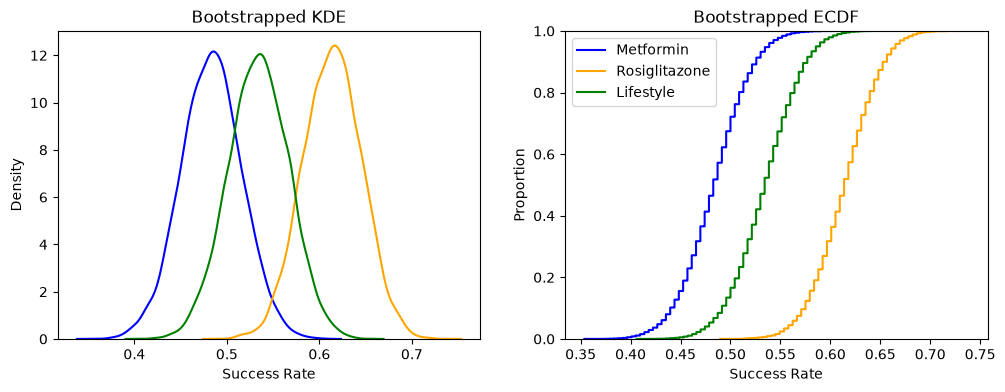

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='Metformin', color='blue', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[0])
sns.kdeplot(outcome_lifestyle, label='Lifestyle', color='green', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_met, label='Metformin', color='blue', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[1])
sns.ecdfplot(outcome_lifestyle, label='Lifestyle', color='green', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')

plt.legend()
plt.show()

Observed success rates were 53 percent for Lifestyle, 48 percent for Metformin, and 61 percent for Rosiglitazone. All three bootstrapped distributions are approximately normal with similar variance and different means. Lifestyle overlaps substantially with both Metformin and Rosiglitazone, whereas Metformin and Rosiglitazone show little overlap.

| Comparison | 90 percent CI | 95 percent CI | 99 percent CI | Significant |
|---|---|---|---|---|
| Metformin vs Rosiglitazone | -0.204 to -0.054 | -0.217 to -0.041 | -0.247 to -0.011 | At all three levels |
| Metformin vs Lifestyle | -0.129 to 0.026 | -0.142 to 0.043 | -0.172 to 0.069 | None |
| Rosiglitazone vs Lifestyle | 0.007 to 0.157 | -0.010 to 0.169 | -0.036 to 0.195 | At 90 percent only |

For Metformin vs Rosiglitazone, zero falls outside all three intervals, with the 99 percent interval spanning -0.247 to -0.011, so the difference is statistically significant at every level and favors Rosiglitazone. For Metformin vs Lifestyle, zero falls inside all three intervals, so there is no statistically significant difference. For Rosiglitazone vs Lifestyle, zero falls outside the 90 percent interval, which spans 0.007 to 0.157, but inside the 95 and 99 percent intervals, so that difference is statistically significant only at the 90 percent level.

Rosiglitazone shows the strongest evidence of benefit, with a statistically significant advantage over Metformin at all three levels and over Lifestyle at the 90 percent level. Metformin shows no evidence of benefit over either alternative and is the only arm with a demonstrated deficit, so it has the weakest case of the three. The evidence for Lifestyle is inconclusive. It cannot be separated from Metformin, and it cannot be distinguished from Rosiglitazone beyond the 90 percent level, so the trial neither supports adopting it nor rules it out.

Some caveats apply to this analysis. No adjustments were made for multiple comparisons, which increases the chance of a false positive. The sample sizes per arm are somewhat limited, so small differences in effect between the groups would be unlikely to reach significance. The analysis only considers success and failure rates, so other factors such as costs, adherence, and side effects are not taken into account.

### AI Acknowledgment

AI assistance was used to generate portions of the analysis code and to edit the wording of the written answers and report. I ran all of the code, and I can explain the analysis and results.